In [1]:
import numpy as np # Numpy is used for math and stats in python 
import pandas as pd # Pandas is used for handling data in a spreadsheet like way
import matplotlib.pyplot as plt  # Matplotlib is used for plotting

In [2]:
# If the alphaMELTS for Python files have not been added to your Python path (see installation guide) then use the two lines below to add
# the location of the alphaMELTS files here.

# import sys
# sys.path.append(r'C:\Users\penny\Box\Berkeley_new\MELTS_Installation\alphamelts_py\alphamelts-py-2.3.1-win64')


import petthermotools as ptt 

print(ptt.__version__)

alphaMELTS for Python files successfully located.
If you are planning on using the Green et al. (2025) or Weller et al. (2024) thermodynamic models through MAGEMin for crystallization, melting, or phase diagram calculations
you will need to run `ptt.activate_petthermotools_env()` at the start of each notebook, prior to any calculations, every time you restart the kernel. 
This step establishes the python-julia connection and sets up the julia workers. Expect it to take about 20-40s on most machines.
1.3.8


# Part 1 - A brief introduction

Over this summer I have been working on developing a trace element engine to work alongside PetThermoTools. At the moment the engine works as a post-processing step, calculating trace element distribution between phases as a function of phase proportion and mineral-melt (or mineral-mineral) partition coefficients. This is still an active area of development and will likely expand rapidly in the next few months to years. If you have a request for a trace element partitioning model that you'd like to see included then please let me know!

To view the currently implemented trace element models we can use the functions `ptt.show_trace_models()` and `ptt.show_trace_citations()`:

In [3]:
ptt.show_trace_models()

{
    'pyroxene': {
        'Wood1997': 'Clinopyroxene partitioning model for 3+ cations on the M2 site from Wood and Blundy 1997.',
        'Sun2012': 'Clinopyroxene partitioning model for 3+ cations (REE + Y) on the M2 site. Benchmarked against the excel macro file from Prof. Chenguang Sun. Original studies - Sun and Liang (2012, 2014).',
        'Sun2013': 'Orthopyroxene (low-Ca pyroxene) partitioning model. Benchmarked against the excel macro file from Prof. Chenguang Sun. Original studies - Sun and Liang (2013 2014); Liang et al. (2012).',
    },
    'olivine': {
        'Beattie1991': 'Olivine partitioning models from Beattie et al. (1991), including Ca, Sc, Mn, Ni, Co, and Yb',
        'Sun2014': 'Olivine partitioning model for 3+ cations (REE + Y). Benchmarked against the excel macro file from Prof. Chenguang Sun. Original study - Sun and Liang (2014).',
    },
    'garnet': {
        'Sun2013': 'Garnet partitioning model for 3+ cations (REE + Y). Benchmarked against the excel 

In [4]:
ptt.show_trace_citations()

{
    'pyroxene': {
        'Wood1997': [
            'Wood, B.J. and Blundy, J.D., 1997. A predictive model for rare earth element partitioning between clinopyroxene and anhydrous silicate melt. Contributions to Mineralogy and Petrology, 129(2), pp.166-181.',
        ],
        'Sun2012': [
            'Sun, C. and Liang, Y., 2012. Distribution of REE between clinopyroxene and basaltic melt along a mantle adiabat: effects of major element composition, water, and temperature. Contributions to Mineralogy and Petrology, 163(5), pp.807-823.',
            'Sun, C. and Liang, Y., 2014. An assessment of subsolidus re-equilibration on REE distribution among mantle minerals olivine, orthopyroxene, clinopyroxene, and garnet in peridotites. Chemical Geology, 372, pp.80-91.',
        ],
        'Sun2013': [
            'Yao, L., Sun, C. and Liang, Y., 2012. A parameterized model for REE distribution between low-Ca pyroxene and basaltic melts with applications to REE partitioning in low-Ca pyroxen

To demonstrate how the trace element engine works 'below the hood' we can quickly do a preview calculation with some mineral data, here calculating the clinopyroxene-melt partition coefficients for the clinopyroxene compositions given by Sun and Liang (2012) in their excel macro.

Each mineral group has its own calculator:

- `ptt.PxTraceElementCalculator()` for clinopyroxene and low-Ca pyroxene
- `ptt.OlTraceElementCalculator()` for olivine
- `ptt.GrtTraceElementCalculator()` for garnet

Each calculator has a `calculate_partitioning` method that takes:

- `data`: the mineral major-element compositions, in wt%, with a phase suffix such as _Cpx
- `liquid`: the melt composition (optional). The Sun & Liang (2012) model uses only the melt H2O content.
- `temperature_c` and pressure_bar: the conditions for each analysis
- `model_name`: which partitioning model to use - the available models for each phase group can be seen above. 

The calculate partitioning method returns a DataFrame of D values with one row per analysis and one column per element.

In [5]:
cpx = pd.DataFrame({
    'T_C':       [1160, 1180, 1170, 1160, 1160, 1100, 1100, 1050, 1075, 1245],
    'P_bar':     [10000]*10,
    'H2O_Liq':   [17.35, 16.30, 9.90, 9.90, 8.50, 12.00, 11.00, 14.10, 5.80, 1.64],
    'SiO2_Cpx':  [51.31, 53.65, 52.53, 52.53, 52.99, 52.50, 52.57, 52.89, 51.80, 49.67],
    'TiO2_Cpx':  [0.46, 0.57, 0.61, 0.74, 0.58, 0.58, 0.70, 0.55, 1.20, 0.42],
    'Al2O3_Cpx': [5.91, 5.73, 6.88, 6.73, 5.46, 4.33, 3.72, 3.19, 3.70, 7.50],
    'Cr2O3_Cpx': [0.02, 0.07, 0.23, 0.21, 0.27, 0.24, 0.27, 0.18, 0.90, 0.56],
    'FeOt_Cpx':  [6.61, 4.54, 6.28, 6.65, 6.19, 6.11, 5.72, 6.82, 5.39, 5.08],
    'MnO_Cpx':   [0.06, 0.10, 0.17, 0.17, 0.15, 0.16, 0.16, 0.16, 0.11, 0.14],
    'MgO_Cpx':   [12.76, 14.91, 16.49, 16.18, 17.24, 17.00, 16.81, 16.25, 15.38, 17.96],
    'CaO_Cpx':   [18.59, 16.74, 14.21, 15.30, 16.02, 17.32, 19.26, 18.62, 21.44, 16.86],
    'Na2O_Cpx':  [2.87, 2.69, 1.88, 1.67, 1.33, 1.14, 0.79, 0.86, 0.61, 0.95],
    'K2O_Cpx':   [0.02, 0.01, 0.00, 0.01, 0.01, 0.01, 0.02, 0.01, 0.02, 0.00],
})

D = ptt.PxTraceElementCalculator().calculate_partitioning(
    data=cpx.filter(like='_Cpx'),
    liquid=cpx[['H2O_Liq']],
    temperature_c=cpx['T_C'],
    pressure_bar=cpx['P_bar'],
    model_name='Sun2012')
D


,La,Ce,Pr,Nd,Sm,Eu,Gd,Tb,Dy,Y,Ho,Er,Tm,Yb,Lu
0,0.041256,0.068543,0.104702,0.147384,0.222315,0.246798,0.262432,0.267569,0.261846,0.253285,0.247718,0.228654,0.207613,0.186770,0.167514
1,0.027540,0.046249,0.072235,0.105135,0.172672,0.200882,0.225155,0.243344,0.253826,0.256038,0.255905,0.251373,0.242283,0.230566,0.217817
2,0.037093,0.061534,0.096102,0.141525,0.243979,0.292946,0.340974,0.385003,0.422009,0.440127,0.447655,0.462618,0.468514,0.467414,0.461455
3,0.039650,0.066522,0.104685,0.154784,0.266471,0.318731,0.368878,0.413381,0.448908,0.465098,0.471377,0.482006,0.482979,0.476856,0.466146
4,0.039964,0.067248,0.105966,0.156637,0.268529,0.320152,0.369014,0.411518,0.444357,0.458603,0.463845,0.471475,0.469650,0.461078,0.448332
5,0.045049,0.077983,0.125278,0.187147,0.320214,0.378466,0.430471,0.471604,0.498100,0.506048,0.507523,0.503001,0.488451,0.467729,0.444139
6,0.051359,0.088656,0.141230,0.208075,0.343019,0.397000,0.440922,0.470385,0.482486,0.480814,0.477408,0.459733,0.434238,0.405083,0.375458
7,0.049778,0.087802,0.142615,0.213788,0.361578,0.422344,0.472874,0.508008,0.524171,0.523987,0.521012,0.503429,0.476684,0.445447,0.413342
8,0.085347,0.146384,0.229608,0.330161,0.510779,0.570600,0.608891,0.621342,0.606987,0.585763,0.572012,0.525137,0.473755,0.423219,0.376877
9,0.070552,0.115416,0.177354,0.256419,0.425737,0.501946,0.573036,0.633928,0.680068,0.699577,0.706563,0.715871,0.711637,0.697848,0.678238


However, the trace element doesn't only work by these in-built models. You can also supply your own partition coefficients (at this point only fixed values) to the code for any element of interest. As a default, the code falls back on the partition coefficients of Gibson and Geist (2010) as the 'standard' partition coefficients for most trace elements if users do not select a model or specify their own coefficients.

# Part 2 - Mineral trace chemistry

One of the topics I worked on at the start of my PhD was the use of olivine minor and trace element chemistry as a way to track the relative contribution of pyroxenite and lherzolite components in the source region of ocean island basalts. The theory is that olivine poor lithologies produce melts with higher Ni contents and then those high Ni contents are recorded in the composition of olivine phenocrysts (Sobolev et al. 2005; 2007). In the first paper of my PhD I painstakingly ran, by hand, hundreds of crystallization models to show that progressive magma mixing could cause an enrichment in olivine Ni contents without the need for any variation in mantle lithology (Gleeson and Gibson, 2019). While this remains my most highly cited paper it's frustrating to know that what took me months at the time (individually typing compositions into Petrolog3) I could now do in approximately 1 hour with PetThermoTools and the new trace element engine...

![Figure from Harpp and Geist (2018) of the Galapagos Islands](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS_UYqdZtATJP_fwtoRB4C4a6mvjuarOrz_avV_5msHOVWktslgJrXqRIc&s=10)

<img src="EGalapOl.png" alt="Figure 2 from Gleeson and Gibson (2019)" width="600">

So, what we're going to do is take some olivine data from Santa Cruz in the Galapagos Islands (the focus of my 2019 paper) and see if we can recreate the olivine Ni contents through fractional crystallization. As an 'extra' assignment I'm going to leave you some space to see if you can create a model where periodic magma recharge (mixing with the new primary magma) occurs and examine the influence on olivine Ni contents. I'll post my 'answer' to this problem in the Discord on Friday.

To start we'll load a single composition of a high-MgO basalt from Santa Cruz and run a simple fractional crystallization model:

In [6]:
#### Whole-rock composition of Santa Crux basalt from Harpp and Weis 2020
comp = {'SiO2_Liq': 46.68,
        'TiO2_Liq': 1.05,
        'Al2O3_Liq': 16.37,
        'Cr2O3_Liq': 0.0,
        'FeOt_Liq': 10.15,
        'CaO_Liq': 11.21,
        'MgO_Liq': 11.93,
        'MnO_Liq': 0.17,
        'K2O_Liq': 0.09,
        'Na2O_Liq': 2.24,
        'P2O5_Liq': 0.11}

In [7]:
frac_xtal = ptt.isobaric_crystallisation(Model = "MELTSv1.0.2",
                                         bulk = comp,
                                         P_bar=2000,
                                         fO2_buffer="FMQ",
                                         fO2_offset=-1,
                                         H2O_init=0.2,
                                         find_liquidus=True,
                                         dt_C=2,
                                         T_end_C = 600,
                                         MgO_limit=5)

multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).


(<Figure size 500x350 with 1 Axes>,
 <Axes: xlabel='MgO_Liq', ylabel='Mass fraction'>)

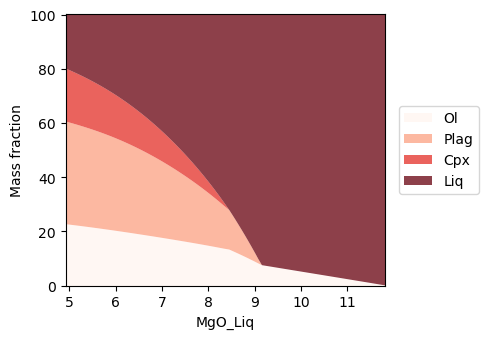

In [8]:
ptt.phase_plot(Results=frac_xtal, x_axis = "MgO_Liq")

Now we have a crystallization model, with information about the mass and composition of each phase, we can apply published partitioning models to estimate the trace element content of different phases. At the moment the only partitioning model for Ni that I have added to the trace element engine is the olivine-melt partitioning model from Beattie et al. (1991). For other phases we will specify fixed partition coefficients.

First let's outline the partitioning models and partition coefficients we'll use for each phase:

In [9]:
### first specify that we will use the Beattie et al. 1991 parameterization for olivine-melt partitioning
partition_models = {"ol": "Beattie1991"}

### next specify the mineral-melt partition coeffs for clinopyroxene, orthopyroxene, plagioclase
D_coeffs = {'clinopyroxene': {'Ni': 3.0},
            'orthopyroxene': {'Ni': 5.0},
            'plagioclase': {'Ni': 0.05},
            'spinel': {'Ni': 10.0}}

Have a look at the structure. The partition coefficients and models are defined by dictionaries, with the upper level 'keys' representing the name of the phase (i.e., 'ol', 'olivine', 'cpx', 'clinopyroxene', etc.). For partition models the values are simply a string variable matching any of the registered partition models for that phase. When specifying partition coefficients the values in the dictionaries are sub dictionary, containing element name combined with the user specified partition coefficient.

The main function in the trace element engine that you need to use to determine trace element partitioning behaviour is `te.calc_trace_conc`, which takes the PetThermoTools output from a melting, crystallization or equilibration model, some information on the initial concentration of the trace elements of interest, and information on the partitioning behaviour:

In [10]:
trace_conc, trace_d = ptt.calc_trace_conc(results = frac_xtal, 
                                initial_conc = {"Ni": 250.0}, 
                                partition_models = partition_models,
                                D_coeffs = D_coeffs)

This function has two outputs. The first is the concentration of each trace element in each phase that saturated in the model. The second is the partition coefficients for each phase. Examining this second output can be useful for ensuring that the partitioning models are behaving as expected!

In [11]:
trace_d['olivine1']

,Ni
0,9.310170
1,9.385468
2,9.461326
3,9.537749
4,9.614742
...,...
83,19.528742
84,19.818073
85,20.120471
86,20.436243


In [12]:
trace_params = {'initial_conc': {"Ni": 250.0},
                'partition_models': partition_models,
                'D_coeffs': D_coeffs}


frac_xtal, trace_conc, trace_d = ptt.isobaric_crystallisation(Model = "MELTSv1.0.2",
                                         bulk = comp,
                                         P_bar=2000,
                                         fO2_buffer="FMQ",
                                         fO2_offset=-1,
                                         H2O_init=0.2,
                                         find_liquidus=True,
                                         dt_C=2,
                                         T_end_C = 600,
                                         MgO_limit=5,
                                         trace_params = trace_params)

multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).


Now we have trace data, let's compare the predictions against some real data.

The dataset below represents olivine compositions I measured from Santa Cruz basalts. In the cells below plot the compositions of olivine 07DSG84 against the trace element predictions from our thermodynamic mdoels.

In [13]:
ol_data = pd.read_excel("SantaCruzOlivine.xlsx")
ol_data.head()

,Sample,Crystal no.,Rim analyses,Distance (µ),FeO,SiO2,MgO,Al2O3,CaO,MnO,NiO,Total,Ni (ppm),Fe/Mn,Ca (ppm),Ni*FeO/MgO,Fo
0,07DSG82,1,Rim,NaN,20.9599,39.3080,40.5958,0.1544,0.3927,0.3350,0.1340,101.9601,1052.968372,62.797198,2806.590641,543.655052,77.531788
1,07DSG82,1,NaN,NaN,15.4830,40.3744,45.1594,0.0897,0.2576,0.2232,0.2511,101.9062,1973.137001,69.623650,1841.043415,676.494377,83.861905
2,07DSG82,1,Rim,NaN,20.5164,39.5755,40.6841,0.0973,0.3828,0.3341,0.1400,101.8313,1100.116209,61.634027,2735.836255,554.772606,77.939527
3,07DSG82,1,NaN,NaN,14.6074,40.9186,45.2231,0.1006,0.2513,0.2153,0.2775,101.6544,2180.587486,68.096495,1796.017897,704.346090,84.652639
4,07DSG82,1,NaN,NaN,16.4464,39.5179,44.6006,0.1873,0.2669,0.2469,0.2308,101.5555,1813.620151,66.856806,1907.509656,668.769533,82.851991


Text(0, 0.5, 'Ni (ppm)')

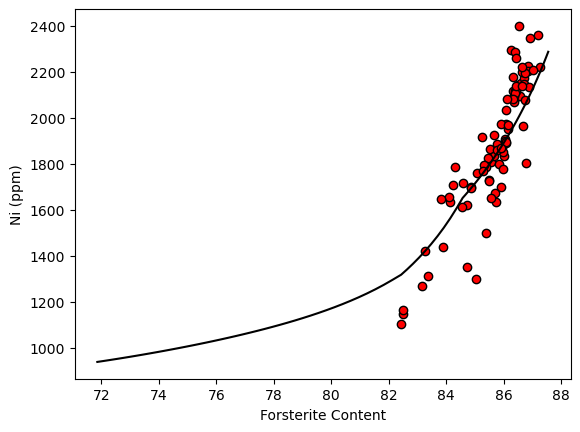

In [14]:
## plot the olivine data
plt.plot(ol_data.loc[ol_data['Sample'] == "07DSG84", 'Fo'],
         ol_data.loc[ol_data['Sample'] == "07DSG84", 'Ni (ppm)'], 'ok', mfc = 'r')

## plot the model predictions
plt.plot(100*(frac_xtal['olivine1']['MgO_Ol']/40.3044)/(frac_xtal['olivine1']['MgO_Ol']/40.3044 + frac_xtal['olivine1']['FeOt_Ol']/71.844),
         trace_conc['olivine1']['Ni'], '-k')

## label axes
plt.xlabel('Forsterite Content')
plt.ylabel('Ni (ppm)')

# Part 2 - More complex and accounting for mixing

In your own time try to create a model that accounts for primitive magma recharge, mixing the evolved, fractionated melts with new incoming magmas. Hopefully you'll find what I did in 2019, that magma mixing can shoft the Fo vs Ni curve to higher Ni contents helping to explain the rest of the olivine Ni data

In [20]:
frac_xtal_m = {}
trace_conc_m = {}
trace_d_m = {}

prop_all = [0.2,0.15,0.1]

for i in range(3):
    if i == 0:
        bulk = pd.Series(comp)

        trace_params = {'initial_conc': {"Ni": 250.0},
                    'partition_models': partition_models,
                    'D_coeffs': D_coeffs}
    else:
        bulk = new_bulk

        trace_params = {'initial_conc': {"Ni": new_Ni},
                    'partition_models': partition_models,
                    'D_coeffs': D_coeffs}



    frac_xtal_m[i], trace_conc_m[i], trace_d_m[i] = ptt.isobaric_crystallisation(Model = "MELTSv1.0.2",
                                            bulk = bulk,
                                            P_bar=2000,
                                            fO2_buffer="FMQ",
                                            fO2_offset=-1,
                                            H2O_init=0.2,
                                            find_liquidus=True,
                                            dt_C=2,
                                            T_end_C = 600,
                                            MgO_limit=6,
                                            Frac_solid = True,
                                            trace_params = trace_params)

    starting_comp_1 = frac_xtal_m[0]['liquid1'].iloc[0]
    prop = prop_all[i]
    new_bulk = frac_xtal_m[i]['liquid1'].iloc[-1]*prop+(1-prop)*starting_comp_1
    new_Ni = trace_conc_m[i]['liquid1']['Ni'].iloc[-1]*prop+(1-prop)*250.0

multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).
multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).
multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/1 [00:00<?, ?it/s]

multi_path_v2: 1/1 completed, 0/1 returned partial results after a crash, 0/1 returned partial results after timing out, 0/1 returned no results (no retry by default -- see max_retries).


Text(0, 0.5, 'Ni (ppm)')

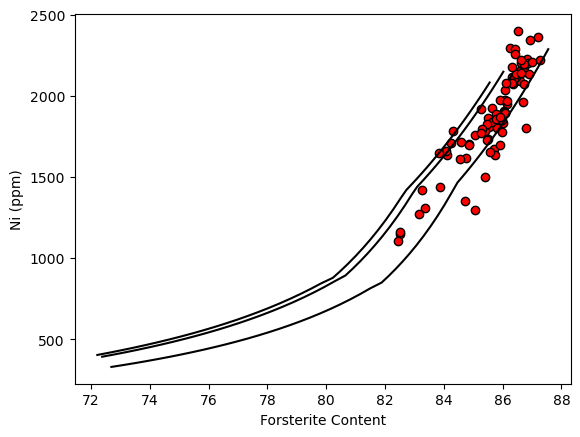

In [21]:
## plot the olivine data
plt.plot(ol_data.loc[ol_data['Sample'] == "07DSG84", 'Fo'],
         ol_data.loc[ol_data['Sample'] == "07DSG84", 'Ni (ppm)'], 'ok', mfc = 'r')

## plot the model predictions
for i in frac_xtal_m:
    MgO_olivine = frac_xtal_m[i]['olivine1']['MgO_Ol']
    FeOt_olivine = frac_xtal_m[i]['olivine1']['FeOt_Ol']
    Fo_model = 100*((MgO_olivine/ptt.OXIDE_MW['MgO'])/(MgO_olivine/ptt.OXIDE_MW['MgO'] + FeOt_olivine/ptt.OXIDE_MW['FeO']))
    plt.plot(Fo_model, trace_conc_m[i]['olivine1']['Ni'], '-k')

## label axes
plt.xlabel('Forsterite Content')
plt.ylabel('Ni (ppm)')


# Part 3 - Mantle melting

One of the other common things that people want to use trace elements for is calculating the composition of magmas formed by mantle melting in different tectonic settings. I'm still actively working on developing the melting functions to include multiple, compositionally distinct but thermally equilibrated components but an early version of the melting code (accounting for a single lithology) is already available.

Within PetThermoTools there are several saved compositions. One of which is the KLB-1 lherzolite of Hirose (1993). Below is an example of how we can run a melting model for the KLB-1 lherzolite at a user specified potential temperature:

In [19]:
frac_melt = ptt.AdiabaticDecompressionMelting(Model = "pMELTS",
                                              bulk = "KLB-1",
                                              P_start_bar=30000,
                                              P_end_bar=2000,
                                              dp_bar=200,
                                              Tp_C=1350,
                                              Frac = True)

In [20]:
frac_melt['All']['MgO_Liq']

0            NaN
1            NaN
2            NaN
3            NaN
4            NaN
         ...    
136    10.971218
137    10.977924
138    10.992875
139    11.056007
140    11.172644
Name: MgO_Liq, Length: 141, dtype: float64

(<Figure size 400x500 with 1 Axes>,
 <Axes: xlabel='Mass fraction', ylabel='Pressure (bar)'>)

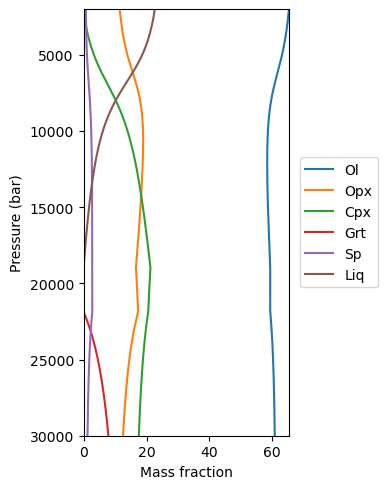

In [21]:
ptt.phase_plot(Results = frac_melt, y_axis = "P_bar", cmap = "viridis", lines=True)


(<Figure size 400x500 with 1 Axes>,
 <Axes: xlabel='Mass fraction', ylabel='Pressure (bar)'>)

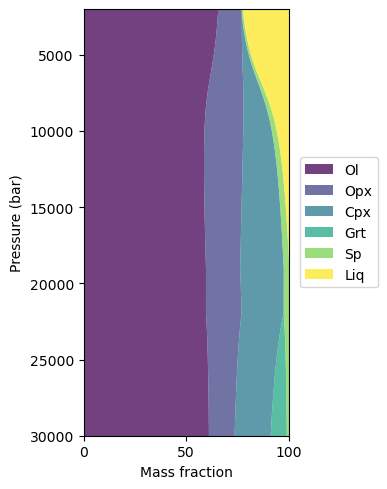

In [22]:
ptt.phase_plot(Results = frac_melt, y_axis = "P_bar", cmap = "viridis")

Included in the beta version of the trace element engine are parameterizations for the partitioning of 3+ cations (REE + Y) between melt and the major mantle phases, olivine, clinopyroxene, orthopyroxene, and garnet. All of these models come from the same group (e.g., Sun and Liang, 2012; 2013; 2014). As before, we can set up our partitioning models and then run the results of the thermodynamic model through the trace element engine.

In [23]:
partition_models = {"cpx": "Sun2012",
                    "opx": "Sun2013",
                    "ol": "Sun2014",
                    "grt": "Sun2013"}

We can also use the starting composition of the Workman and Hart (2005) for our trace element calcs:

In [24]:
workman05_dmm = ptt.trace_comps['workman05_dmm']

In [25]:
trace_conc, trace_d = ptt.calc_trace_conc(results = frac_melt, 
                                initial_conc = workman05_dmm, 
                                partition_models = partition_models)

Let's plot the melt trace element content against pressure to see how the concentration of La and Yb in melts change as melting progresses. Note these are the 'instanteous' melt concentrations as we are simulating fractional crystallization in this example:

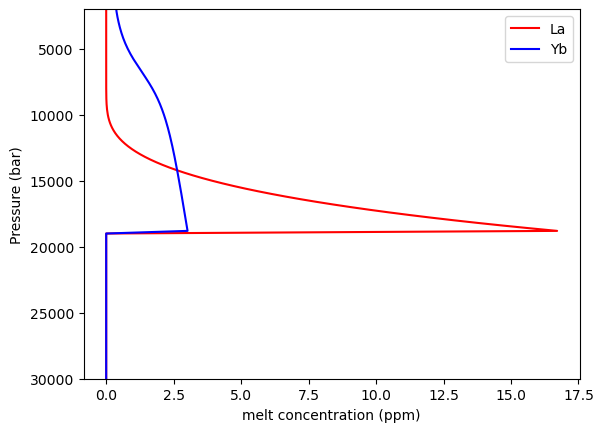

In [26]:
plt.plot(trace_conc['liquid1']['La'], 
         frac_melt['All']['P_bar'], '-r', label = 'La')
plt.plot(trace_conc['liquid1']['Yb'],
         frac_melt['All']['P_bar'], '-b', label = 'Yb')

plt.ylim([30000,2000])
plt.ylabel('Pressure (bar)')
plt.xlabel('melt concentration (ppm)')

plt.legend()

# Part 4 - Calculating accumulated melt compositions

I predict that we won't get around to this in the session. So in your own time calculate the concentration of La and Yb in the accumulated melt phase in a mid-ocean ridge and an ocean island setting. I'll post my workings early next week in the discord server!

<Axes: ylabel='Sample / CI chondrite'>

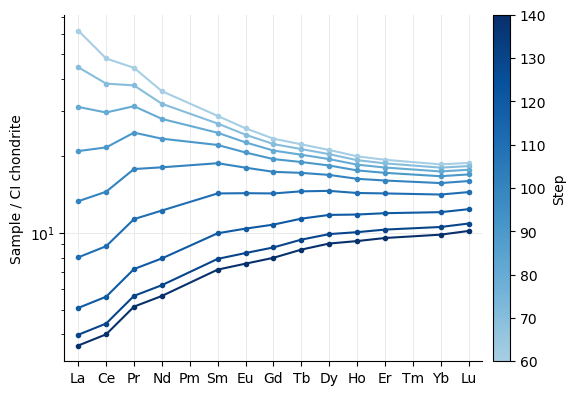

In [27]:
ptt.plot_ree(ptt.calc_accumulated_melt(frac_melt, trace_conc), every = 10)